In [1]:
import geopandas as gpd
import pandas as pd

# ---------------------------------------------------------
# 1. Load the saved impacts layer
# ---------------------------------------------------------
fname = '../out/san_mateo_impacts.gpkg'

impacts = gpd.read_file(
    fname,
    layer='impacts_projected'
)

# Ensure dates are datetime objects
impacts['date'] = pd.to_datetime(
    impacts['date'],
    errors='coerce',
    utc=True
)

# ---------------------------------------------------------
# 2. Define the two time periods (inclusive)
# ---------------------------------------------------------
periods = {
    'period_2017': ('2017-01-01', '2017-02-28'),
    'period_2022_2023': ('2022-12-15', '2023-01-15')
}

# ---------------------------------------------------------
# 3. Create a daily impact count DataFrame for each period
# ---------------------------------------------------------
daily_summaries = {}

for period_name, (start_date, end_date) in periods.items():

    start = pd.Timestamp(start_date, tz='UTC')
    end = pd.Timestamp(end_date, tz='UTC') + pd.Timedelta(days=1)

    # Subset to the selected period
    subset = impacts.loc[
        (impacts['date'] >= start) &
        (impacts['date'] < end)
    ].copy()

    # Group by day and count impacts
    daily_summary = (
        subset.assign(date=subset['date'].dt.floor('D'))
        .groupby('date')
        .size()
        .reset_index(name='n_impacts')
        .sort_values('date')
        .reset_index(drop=True)
    )

    daily_summaries[period_name] = daily_summary

# ---------------------------------------------------------
# 4. Access each summary DataFrame
# ---------------------------------------------------------
daily_2017 = daily_summaries['period_2017']
daily_2022_2023 = daily_summaries['period_2022_2023']

print('January-February 2017:')
print(daily_2017)

print('\nDecember 2022-January 2023:')
print(daily_2022_2023)

daily_2017.to_csv(
    '../out/daily_impacts_2017.csv',
    index=False
)

daily_2022_2023.to_csv(
    '../out/daily_impacts_2022_2023.csv',
    index=False
)

January-February 2017:
                       date  n_impacts
0 2017-01-09 00:00:00+00:00          1
1 2017-01-11 00:00:00+00:00          2
2 2017-01-19 00:00:00+00:00          1
3 2017-02-07 00:00:00+00:00          1
4 2017-02-09 00:00:00+00:00          1
5 2017-02-20 00:00:00+00:00          1
6 2017-02-21 00:00:00+00:00         11

December 2022-January 2023:
                       date  n_impacts
0 2022-12-31 00:00:00+00:00          1
1 2023-01-01 00:00:00+00:00          3
2 2023-01-05 00:00:00+00:00          1
3 2023-01-09 00:00:00+00:00          1
4 2023-01-10 00:00:00+00:00          1
5 2023-01-15 00:00:00+00:00          5


In [1]:
import os
import sys
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# Read Impacts Geodatabase 
# -------------------------------------------------------------------

impacts = gpd.read_file(
    '../out/san_mateo_impacts.gpkg',
    layer='impacts_wgs84'
)

ar_df = pd.read_csv('../out/san_mateo_ar_database.csv')


ar_impact_df = pd.read_csv("../out/san_mateo_ar-impact_database.csv")

# -------------------------------------------------------------------
# Make sure datetime columns are datetime64
# -------------------------------------------------------------------

ar_df['ar_start'] = pd.to_datetime(ar_df['ar_start'], utc=True)
ar_df['ar_end']   = pd.to_datetime(ar_df['ar_end'], utc=True)

ar_df['smc_start'] = pd.to_datetime(ar_df['smc_start'], utc=True)
ar_df['smc_end']   = pd.to_datetime(ar_df['smc_end'], utc=True)

impacts['date'] = pd.to_datetime(
    impacts['date'],
    utc=True,
    format='mixed'
)

In [5]:
# ARs that have at least one associated impact
arids_with_impacts = ar_impact_df['ARID'].unique()

ar_events = ar_df[
    ar_df['ARID'].isin(arids_with_impacts)
].copy()

print(f"Number of AR events: {len(ar_events)}")

Number of AR events: 65


In [7]:
ar_events['smc_start'] = pd.to_datetime(
    ar_events['smc_start'],
    utc=True
)

ar_events['smc_end'] = pd.to_datetime(
    ar_events['smc_end'],
    utc=True
)

ar_events['duration_hours'] = (
    ar_events['smc_end'] - ar_events['smc_start']
).dt.total_seconds() / 3600

ar_events['duration'] = (
    ar_events['duration_hours']
    .round(1)
    .astype(str)
    + ' h'
)

ar_events

,ARID,ar_start,ar_end,smc_start,smc_end,ar_duration_hr,smc_duration_hr,arid_start,duration_hours,duration
257,2.005123e+11,2005-12-27 00:00:00+00:00,2005-12-31 18:00:00+00:00,2005-12-30 06:00:00+00:00,2005-12-31 18:00:00+00:00,114.0,36.0,2005-12-27 00:00:00,36.0,36.0 h
258,2.006010e+11,2006-01-01 12:00:00+00:00,2006-01-03 00:00:00+00:00,2006-01-01 18:00:00+00:00,2006-01-03 00:00:00+00:00,36.0,30.0,2006-01-01 12:00:00,30.0,30.0 h
373,2.009022e+11,2009-02-15 00:00:00+00:00,2009-02-15 12:00:00+00:00,2009-02-15 06:00:00+00:00,2009-02-15 12:00:00+00:00,12.0,6.0,2009-02-15 00:00:00,6.0,6.0 h
374,2.009022e+11,2009-02-15 06:00:00+00:00,2009-02-22 18:00:00+00:00,2009-02-15 18:00:00+00:00,2009-02-16 12:00:00+00:00,180.0,18.0,2009-02-15 06:00:00,18.0,18.0 h
398,2.009101e+11,2009-10-08 06:00:00+00:00,2009-10-18 06:00:00+00:00,2009-10-13 00:00:00+00:00,2009-10-15 12:00:00+00:00,240.0,60.0,2009-10-08 06:00:00,60.0,60.0 h
...,...,...,...,...,...,...,...,...,...,...
1035,2.024023e+11,2024-02-28 12:00:00+00:00,2024-03-03 06:00:00+00:00,2024-03-02 00:00:00+00:00,2024-03-03 06:00:00+00:00,90.0,30.0,2024-02-28 12:00:00,30.0,30.0 h
1038,2.024033e+11,2024-03-26 12:00:00+00:00,2024-03-28 00:00:00+00:00,2024-03-27 18:00:00+00:00,2024-03-28 00:00:00+00:00,36.0,6.0,2024-03-26 12:00:00,6.0,6.0 h
1039,2.024033e+11,2024-03-30 00:00:00+00:00,2024-04-05 00:00:00+00:00,2024-03-30 00:00:00+00:00,2024-03-30 00:00:00+00:00,144.0,0.0,2024-03-30 00:00:00,0.0,0.0 h
1065,2.024121e+11,2024-12-12 00:00:00+00:00,2024-12-12 06:00:00+00:00,2024-12-12 06:00:00+00:00,2024-12-12 06:00:00+00:00,6.0,0.0,2024-12-12 00:00:00,0.0,0.0 h


In [8]:
ar_impacts = ar_impact_df.merge(
    impacts[
        [
            'impact_id',
            'impact_type',
            'date'
        ]
    ],
    on='impact_id',
    how='left'
)

In [10]:
impact_counts = (
    ar_impacts
    .groupby(['ARID', 'impact_type'])['impact_id']
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

In [11]:
ar_event_df = ar_events[
    [
        'ARID',
        'smc_start',
        'smc_end',
        'duration_hours',
        'duration'
    ]
].merge(
    impact_counts,
    on='ARID',
    how='left'
)


,ARID,smc_start,smc_end,duration_hours,duration,Debris Flow,Flash Flood,Flood,Hail,Heavy Rain,Landslide
0,2.005123e+11,2005-12-30 06:00:00+00:00,2005-12-31 18:00:00+00:00,36.0,36.0 h,0,0,2,0,0,0
1,2.006010e+11,2006-01-01 18:00:00+00:00,2006-01-03 00:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0
2,2.009022e+11,2009-02-15 06:00:00+00:00,2009-02-15 12:00:00+00:00,6.0,6.0 h,0,0,1,0,0,0
3,2.009022e+11,2009-02-15 18:00:00+00:00,2009-02-16 12:00:00+00:00,18.0,18.0 h,0,0,1,0,0,0
4,2.009101e+11,2009-10-13 00:00:00+00:00,2009-10-15 12:00:00+00:00,60.0,60.0 h,0,0,0,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...
60,2.024023e+11,2024-03-02 00:00:00+00:00,2024-03-03 06:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0
61,2.024033e+11,2024-03-27 18:00:00+00:00,2024-03-28 00:00:00+00:00,6.0,6.0 h,0,0,0,1,0,0
62,2.024033e+11,2024-03-30 00:00:00+00:00,2024-03-30 00:00:00+00:00,0.0,0.0 h,0,0,0,1,0,0
63,2.024121e+11,2024-12-12 06:00:00+00:00,2024-12-12 06:00:00+00:00,0.0,0.0 h,0,0,2,0,0,0


In [12]:
impact_types = [
    'Debris Flow',
    'Flash Flood',
    'Flood',
    'Hail',
    'Heavy Rain',
    'Landslide',
]

for impact_type in impact_types:
    if impact_type not in ar_event_df.columns:
        ar_event_df[impact_type] = 0

ar_event_df

,ARID,smc_start,smc_end,duration_hours,duration,Debris Flow,Flash Flood,Flood,Hail,Heavy Rain,Landslide
0,2.005123e+11,2005-12-30 06:00:00+00:00,2005-12-31 18:00:00+00:00,36.0,36.0 h,0,0,2,0,0,0
1,2.006010e+11,2006-01-01 18:00:00+00:00,2006-01-03 00:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0
2,2.009022e+11,2009-02-15 06:00:00+00:00,2009-02-15 12:00:00+00:00,6.0,6.0 h,0,0,1,0,0,0
3,2.009022e+11,2009-02-15 18:00:00+00:00,2009-02-16 12:00:00+00:00,18.0,18.0 h,0,0,1,0,0,0
4,2.009101e+11,2009-10-13 00:00:00+00:00,2009-10-15 12:00:00+00:00,60.0,60.0 h,0,0,0,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...
60,2.024023e+11,2024-03-02 00:00:00+00:00,2024-03-03 06:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0
61,2.024033e+11,2024-03-27 18:00:00+00:00,2024-03-28 00:00:00+00:00,6.0,6.0 h,0,0,0,1,0,0
62,2.024033e+11,2024-03-30 00:00:00+00:00,2024-03-30 00:00:00+00:00,0.0,0.0 h,0,0,0,1,0,0
63,2.024121e+11,2024-12-12 06:00:00+00:00,2024-12-12 06:00:00+00:00,0.0,0.0 h,0,0,2,0,0,0


In [13]:
ar_event_df['Total'] = ar_event_df[impact_types].sum(axis=1)

ar_event_df = ar_event_df.sort_values(
    'smc_start'
).reset_index(drop=True)

ar_event_df['AR_event'] = [
    f'AR{i:02d}'
    for i in range(1, len(ar_event_df) + 1)
]

ar_event_df = ar_event_df[
    [
        'AR_event',
        'ARID',
        'smc_start',
        'smc_end',
        'duration_hours',
        'duration',
        *impact_types,
        'Total'
    ]
]

ar_event_df

,AR_event,ARID,smc_start,smc_end,duration_hours,duration,Debris Flow,Flash Flood,Flood,Hail,Heavy Rain,Landslide,Total
0,AR01,2.005123e+11,2005-12-30 06:00:00+00:00,2005-12-31 18:00:00+00:00,36.0,36.0 h,0,0,2,0,0,0,2
1,AR02,2.006010e+11,2006-01-01 18:00:00+00:00,2006-01-03 00:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0,1
2,AR03,2.009022e+11,2009-02-15 06:00:00+00:00,2009-02-15 12:00:00+00:00,6.0,6.0 h,0,0,1,0,0,0,1
3,AR04,2.009022e+11,2009-02-15 18:00:00+00:00,2009-02-16 12:00:00+00:00,18.0,18.0 h,0,0,1,0,0,0,1
4,AR05,2.009101e+11,2009-10-13 00:00:00+00:00,2009-10-15 12:00:00+00:00,60.0,60.0 h,0,0,0,0,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,AR61,2.024023e+11,2024-03-02 00:00:00+00:00,2024-03-03 06:00:00+00:00,30.0,30.0 h,0,0,1,0,0,0,1
61,AR62,2.024033e+11,2024-03-27 18:00:00+00:00,2024-03-28 00:00:00+00:00,6.0,6.0 h,0,0,0,1,0,0,1
62,AR63,2.024033e+11,2024-03-30 00:00:00+00:00,2024-03-30 00:00:00+00:00,0.0,0.0 h,0,0,0,1,0,0,1
63,AR64,2.024121e+11,2024-12-12 06:00:00+00:00,2024-12-12 06:00:00+00:00,0.0,0.0 h,0,0,2,0,0,0,2


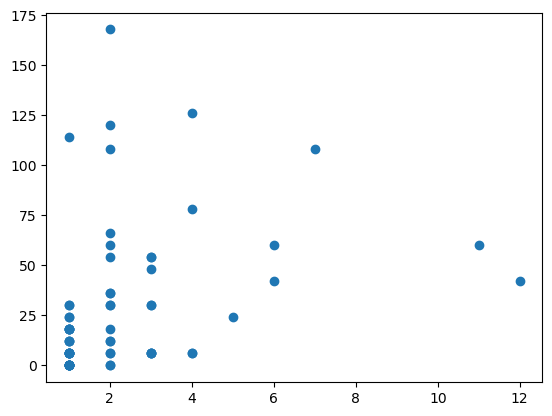

In [14]:
plt.scatter(ar_event_df['Total'], ar_event_df['duration_hours'])

In [15]:
# ------------------------------------------------------------
# Impact types
# ------------------------------------------------------------

impact_types = [
    'Debris Flow',
    'Flash Flood',
    'Flood',
    'Hail',
    'Heavy Rain',
    'Landslide'
]

# ------------------------------------------------------------
# Create one row for every individual impact
# ------------------------------------------------------------

dot_rows = []

for _, row in ar_event_df.iterrows():

    impact_number = 0

    for impact_type in impact_types:

        n = int(row[impact_type])

        for i in range(n):
            impact_number += 1

            dot_rows.append({
                'AR_event': row['AR_event'],
                'ARID': row['ARID'],
                'date': row['smc_start'],
                'impact_type': impact_type,
                'impact_number': impact_number
            })

ar_dot_df = pd.DataFrame(dot_rows)

print(ar_dot_df.head())

  AR_event          ARID                      date impact_type  impact_number
0     AR01  2.005123e+11 2005-12-30 06:00:00+00:00       Flood              1
1     AR01  2.005123e+11 2005-12-30 06:00:00+00:00       Flood              2
2     AR02  2.006010e+11 2006-01-01 18:00:00+00:00       Flood              1
3     AR03  2.009022e+11 2009-02-15 06:00:00+00:00       Flood              1
4     AR04  2.009022e+11 2009-02-15 18:00:00+00:00       Flood              1


In [16]:
impact_colors = {
    'Debris Flow': '#B9A07A',   # light brown / taupe
    'Flash Flood': '#4682B4',   # steel blue
    'Flood': '#87CEEB',         # sky blue
    'Hail': '#808080',          # grey
    'Heavy Rain': '#1F4E79',    # dark blue
    'Landslide': '#8B4513'       # brown
}

impact_sizes = {
    'Debris Flow': 70,
    'Flash Flood': 50,
    'Flood': 45,
    'Hail': 40,
    'Heavy Rain': 45,
    'Landslide': 70
}

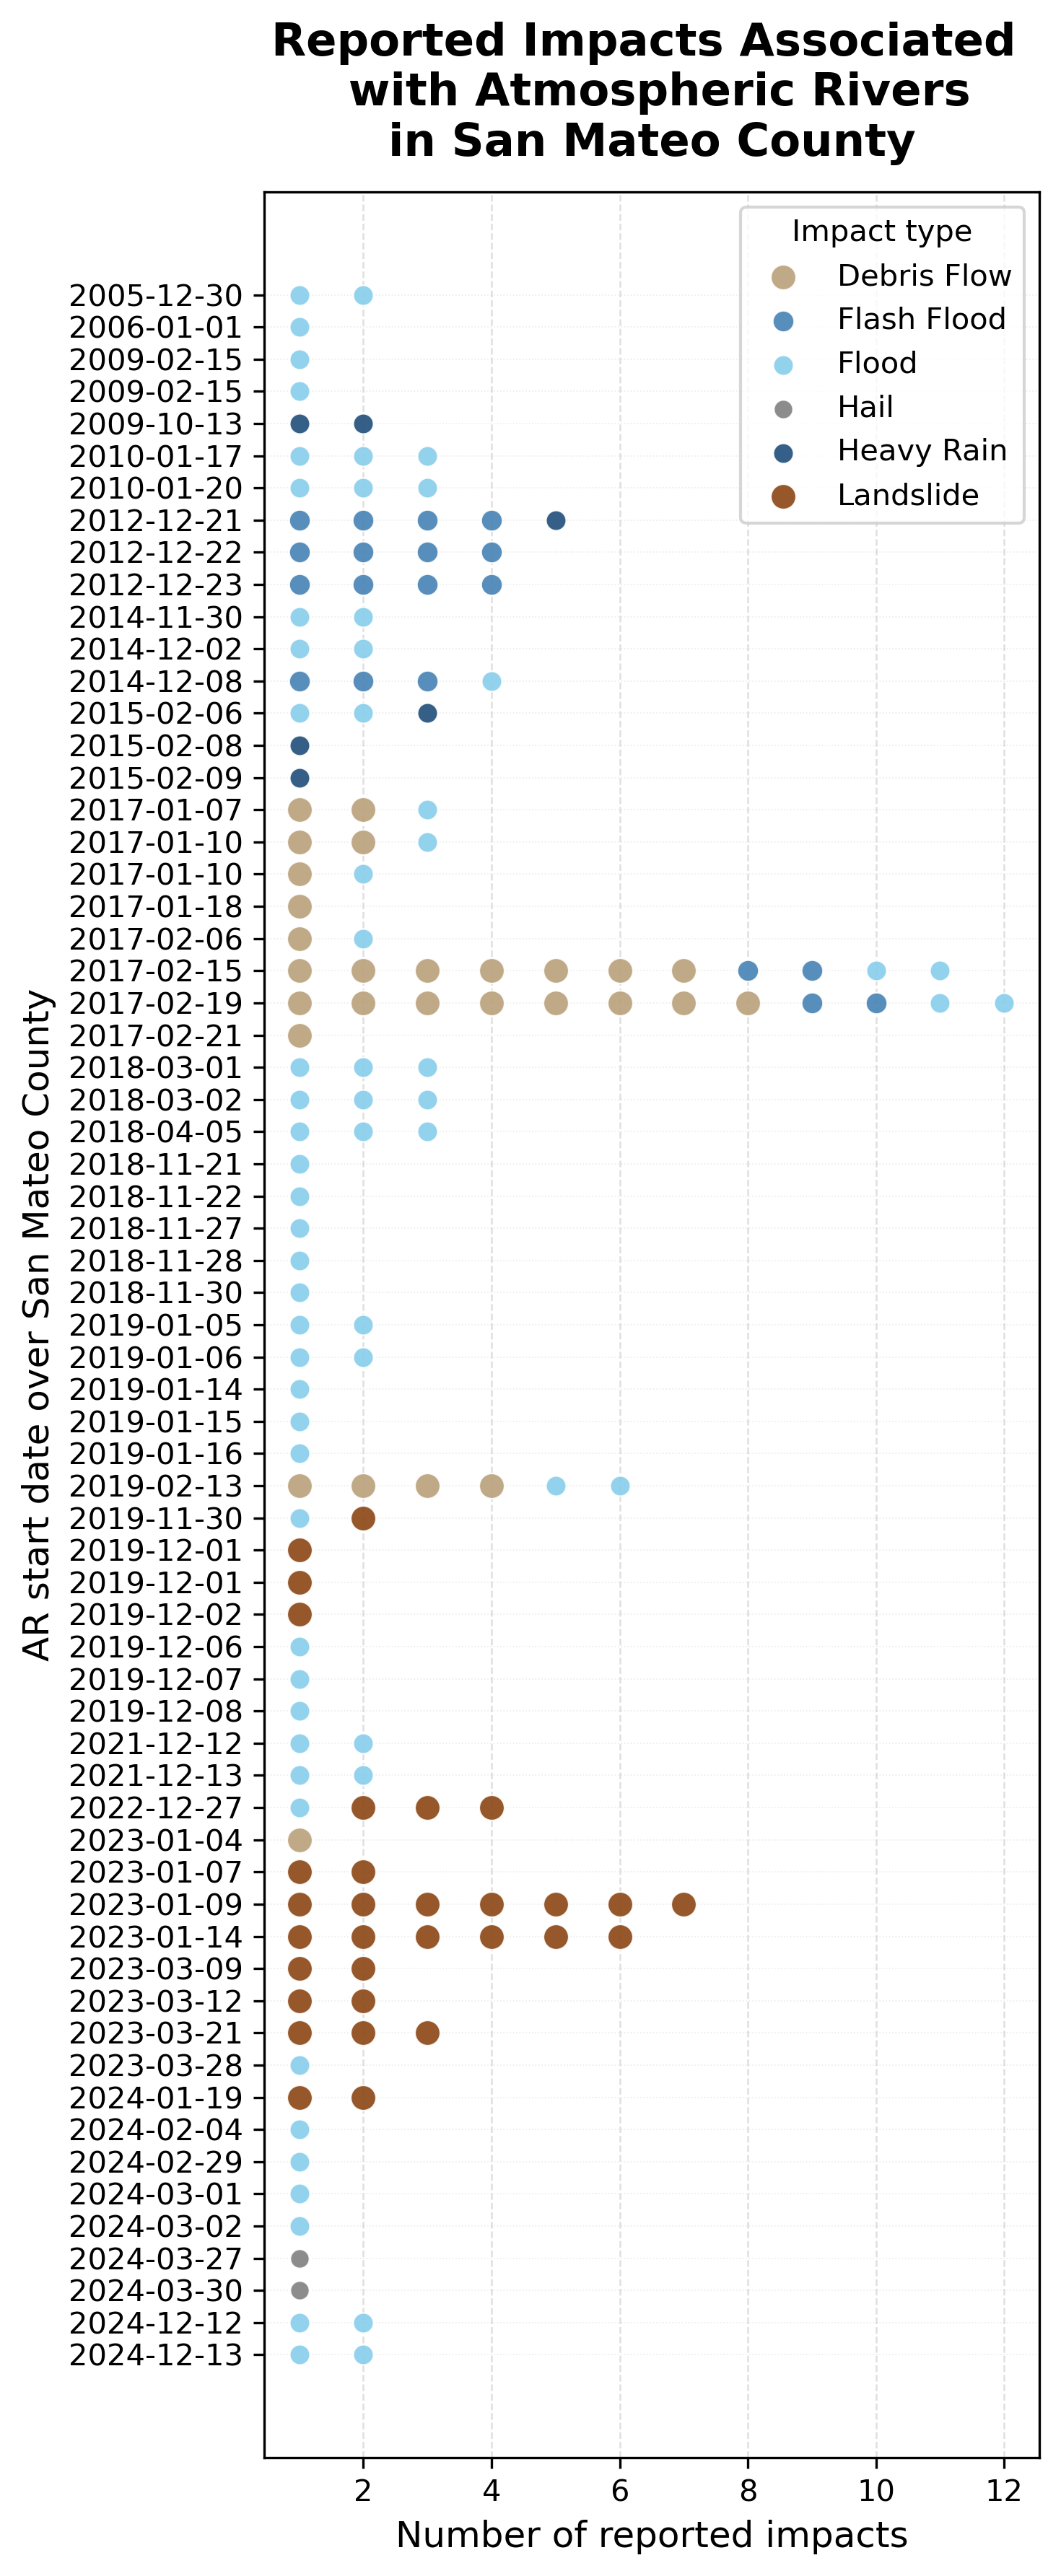

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# ------------------------------------------------------------
# Sort ARs chronologically
# ------------------------------------------------------------

ar_order = (
    ar_event_df
    .sort_values('smc_start')
    ['AR_event']
    .tolist()
)

# Map AR event -> y position
y_positions = {
    ar: i
    for i, ar in enumerate(ar_order)
}

ar_dot_df['y'] = ar_dot_df['AR_event'].map(y_positions)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(5, 12),
    dpi=300
)

# ------------------------------------------------------------
# Plot each impact type
# ------------------------------------------------------------

for impact_type in impact_types:

    subset = ar_dot_df[
        ar_dot_df['impact_type'] == impact_type
    ]

    ax.scatter(
        subset['impact_number'],
        subset['y'],
        s=impact_sizes[impact_type],
        color=impact_colors[impact_type],
        label=impact_type,
        alpha=0.9,
        edgecolor='white',
        linewidth=0.5,
        zorder=3
    )

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(
    range(len(ar_order))
)

# Use the AR date as the label
ar_labels = (
    ar_event_df
    .set_index('AR_event')
    .loc[ar_order, 'smc_start']
    .dt.strftime('%Y-%m-%d')
)

ax.set_yticklabels(ar_labels)

# Put oldest at bottom, newest at top
ax.invert_yaxis()

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xlabel(
    'Number of reported impacts',
    fontsize=12
)

ax.set_ylabel(
    'AR start date over San Mateo County',
    fontsize=12
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.set_axisbelow(True)

ax.grid(
    axis='x',
    linestyle='--',
    linewidth=0.6,
    alpha=0.4
)

ax.grid(
    axis='y',
    linestyle=':',
    linewidth=0.4,
    alpha=0.25
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    title='Impact type',
    loc='upper right',
    frameon=True
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    'Reported Impacts Associated \n with Atmospheric Rivers\n'
    'in San Mateo County',
    fontsize=15,
    fontweight='bold',
    pad=12
)

plt.tight_layout()

plt.show()

In [22]:
# ---------------------------------------------------------------------
# Save Figure
# ---------------------------------------------------------------------

output_path = Path('../figs/AR_event_impacts_dot_plot.png')
fig.savefig(output_path, bbox_inches='tight', dpi=fig.dpi)

print(f"Saved figure to: {output_path.resolve()}")

Saved figure to: /cw3e/mead/projects/cwp140/repos/AR_hazard_tool/figs/AR_event_impacts_dot_plot.png
